In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import griddata
from sklearn.neighbors import NearestNeighbors

import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [7]:
mesh = pd.read_csv('./data/mesh_0p25_vars.csv')
mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,SedimentThickness,UpperCrustThickness,MiddleCrustThickness,LowerCrustThickness,LABDepthZhang,MagneticAnomaly,FreeairAnomaly,BouguerAnomaly
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,4.613889,18.275221,18.004858,6.306364,152.736694,110.039696,-36.014160,-76.160004
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,4.590210,19.881569,18.010675,6.559906,152.652466,55.572872,-15.473985,-96.730003
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,4.746915,20.118238,17.429037,6.005593,152.554840,39.338730,-6.498806,-92.919998
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,5.008747,20.728746,17.118137,5.833605,152.433746,-22.495438,32.711998,-79.330002
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,5.158813,21.218416,16.607227,5.553338,152.279282,-8.775974,98.569221,-95.279999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,2.559528,22.940237,10.542932,1.717799,90.019104,-0.839778,-6.057227,97.309998
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,2.588029,23.116528,10.488193,1.635191,89.534615,104.287445,-2.510353,105.330002
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,2.687839,23.415661,10.564793,1.657960,88.659081,149.677994,9.911932,114.839996
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,2.848825,23.751661,10.791869,1.818924,87.251846,86.479568,14.471847,115.430000


In [8]:
transformer = Transformer.from_crs("EPSG:4326", "EPSG:32649", always_xy=True)
mesh["x"], mesh["y"] = transformer.transform(mesh["lon"].values, mesh["lat"].values)
mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,SedimentThickness,UpperCrustThickness,MiddleCrustThickness,LowerCrustThickness,LABDepthZhang,MagneticAnomaly,FreeairAnomaly,BouguerAnomaly,x,y
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,4.613889,18.275221,18.004858,6.306364,152.736694,110.039696,-36.014160,-76.160004,8.427354e+04,3.771296e+06
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,4.590210,19.881569,18.010675,6.559906,152.652466,55.572872,-15.473985,-96.730003,1.073859e+05,3.770308e+06
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,4.746915,20.118238,17.429037,6.005593,152.554840,39.338730,-6.498806,-92.919998,1.304954e+05,3.769376e+06
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,5.008747,20.728746,17.118137,5.833605,152.433746,-22.495438,32.711998,-79.330002,1.536023e+05,3.768500e+06
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,5.158813,21.218416,16.607227,5.553338,152.279282,-8.775974,98.569221,-95.279999,1.767067e+05,3.767682e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,2.559528,22.940237,10.542932,1.717799,90.019104,-0.839778,-6.057227,97.309998,1.055046e+06,4.448042e+06
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,2.588029,23.116528,10.488193,1.635191,89.534615,104.287445,-2.510353,105.330002,1.076410e+06,4.449637e+06
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,2.687839,23.415661,10.564793,1.657960,88.659081,149.677994,9.911932,114.839996,1.097777e+06,4.451293e+06
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,2.848825,23.751661,10.791869,1.818924,87.251846,86.479568,14.471847,115.430000,1.119145e+06,4.453010e+06


In [9]:
mesh["Elevation"] = mesh["Elevation"].values
mesh["z_CuriePoint"] = mesh["Elevation"].values - mesh["CuriePointDepth"].values * 1e3
mesh["z_LAB"] = mesh["Elevation"].values - mesh["LABDepth"].values * 1e3
mesh["z_Moho"] = mesh["Elevation"].values - mesh["MohoDepth"].values * 1e3
mesh["z_Sediment"] = mesh["Elevation"].values - mesh["SedimentThickness"].values * 1e3
mesh["z_UpperCrust"] = np.maximum(mesh["z_Sediment"].values - mesh["UpperCrustThickness"].values * 1e3, mesh["z_Moho"].values)
mesh["z_MiddleCrust"] = np.maximum(mesh["z_UpperCrust"].values - mesh["MiddleCrustThickness"].values * 1e3, mesh["z_Moho"].values)
mesh["z_LowerCrust"] = mesh["z_Moho"].values

mesh

,lat,lon,HeatFlow,ThermalConductivity,HeatProduction,MohoDepth,CuriePointDepth,LABDepth,LithosphereThicknessXia,Elevation,...,BouguerAnomaly,x,y,z_CuriePoint,z_LAB,z_Moho,z_Sediment,z_UpperCrust,z_MiddleCrust,z_LowerCrust
0,34.0,106.50,60.498493,2.350490,1.558871,46.669300,30.134977,97.760818,118.983490,1279,...,-76.160004,8.427354e+04,3.771296e+06,-28855.9773,-96481.8185,-45390.3001,-3334.8887,-21610.1096,-39614.9676,-45390.3001
1,34.0,106.75,60.498493,2.449945,1.595127,46.921951,29.517136,97.760818,114.524460,1644,...,-96.730003,1.073859e+05,3.770308e+06,-27873.1356,-96116.8185,-45277.9513,-2946.2104,-22827.7793,-40838.4547,-45277.9513
2,34.0,107.00,60.862454,2.349224,1.595127,46.293755,29.090860,107.360710,114.540764,1620,...,-92.919998,1.304954e+05,3.769376e+06,-27470.8604,-105740.7101,-44673.7546,-3126.9153,-23245.1537,-40674.1908,-44673.7546
3,34.0,107.25,60.862454,2.349224,1.565803,45.711952,28.242714,114.510948,112.500000,1860,...,-79.330002,1.536023e+05,3.768500e+06,-26382.7139,-112650.9482,-43851.9522,-3148.7471,-23877.4935,-40995.6309,-43851.9522
4,34.0,107.50,65.266014,2.587953,1.565803,45.392162,27.654491,114.510948,113.374992,2527,...,-95.279999,1.767067e+05,3.767682e+06,-25127.4914,-111983.9482,-42865.1623,-2631.8130,-23850.2292,-40457.4565,-42865.1623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1220,40.0,117.50,58.646114,2.336308,1.196369,35.892410,25.717905,63.426033,168.480225,46,...,97.309998,1.055046e+06,4.448042e+06,-25671.9050,-63380.0330,-35846.4103,-2513.5279,-25453.7649,-35846.4103,-35846.4103
1221,40.0,117.75,58.646114,2.639588,1.196369,35.239433,25.016697,62.425762,149.888123,26,...,105.330002,1.076410e+06,4.449637e+06,-24990.6969,-62399.7622,-35213.4333,-2562.0291,-25678.5567,-35213.4333,-35213.4333
1222,40.0,118.00,66.308685,2.639588,1.196369,34.529862,24.637386,62.425762,132.431595,133,...,114.839996,1.097777e+06,4.451293e+06,-24504.3863,-62292.7622,-34396.8615,-2554.8386,-25970.4995,-34396.8615,-34396.8615
1223,40.0,118.25,66.308685,2.710946,1.164256,34.216644,24.170946,60.751736,119.072441,152,...,115.430000,1.119145e+06,4.453010e+06,-24018.9461,-60599.7357,-34064.6443,-2696.8250,-26448.4863,-34064.6443,-34064.6443


In [10]:
# 构建插值器
lons = np.sort(mesh["lon"].unique())
lats = np.sort(mesh["lat"].unique())

q0_grid = mesh.pivot(index="lat", columns="lon", values="HeatFlow").reindex(index=lats, columns=lons).values
k0_grid = mesh.pivot(index="lat", columns="lon", values="ThermalConductivity").reindex(index=lats, columns=lons).values
A0_grid = mesh.pivot(index="lat", columns="lon", values="HeatProduction").reindex(index=lats, columns=lons).values
elev_grid = mesh.pivot(index="lat", columns="lon", values="Elevation").reindex(index=lats, columns=lons).values
cp_grid = mesh.pivot(index="lat", columns="lon", values="z_CuriePoint").reindex(index=lats, columns=lons).values
lab_grid = mesh.pivot(index="lat", columns="lon", values="z_LAB").reindex(index=lats, columns=lons).values
moho_grid = mesh.pivot(index="lat", columns="lon", values="z_Moho").reindex(index=lats, columns=lons).values
sed_grid = mesh.pivot(index="lat", columns="lon", values="z_Sediment").reindex(index=lats, columns=lons).values
uc_grid = mesh.pivot(index="lat", columns="lon", values="z_UpperCrust").reindex(index=lats, columns=lons).values
mc_grid = mesh.pivot(index="lat", columns="lon", values="z_MiddleCrust").reindex(index=lats, columns=lons).values
lc_grid = mesh.pivot(index="lat", columns="lon", values="z_LowerCrust").reindex(index=lats, columns=lons).values

q0_interp = RegularGridInterpolator((lats, lons), q0_grid, bounds_error=False, fill_value=None)
k0_interp = RegularGridInterpolator((lats, lons), k0_grid, bounds_error=False, fill_value=None)
A0_interp = RegularGridInterpolator((lats, lons), A0_grid, bounds_error=False, fill_value=None)
elev_interp = RegularGridInterpolator((lats, lons), elev_grid, bounds_error=False, fill_value=None)
cp_interp = RegularGridInterpolator((lats, lons), cp_grid, bounds_error=False, fill_value=None)
lab_interp = RegularGridInterpolator((lats, lons), lab_grid, bounds_error=False, fill_value=None)
moho_interp = RegularGridInterpolator((lats, lons), moho_grid, bounds_error=False, fill_value=None)
sed_interp = RegularGridInterpolator((lats, lons), sed_grid, bounds_error=False, fill_value=None)
uc_interp = RegularGridInterpolator((lats, lons), uc_grid, bounds_error=False, fill_value=None)
mc_interp = RegularGridInterpolator((lats, lons), mc_grid, bounds_error=False, fill_value=None)
lc_interp = RegularGridInterpolator((lats, lons), lc_grid, bounds_error=False, fill_value=None)


In [12]:
# 参数
lon_min, lon_max = 106.5, 118.5
lat_min, lat_max = 34.0, 40.0
n_samples = 30000

# 随机在范围内采样 lon, lat
rng = np.random.default_rng(42)
lon_s = rng.uniform(lon_min, lon_max, n_samples)
lat_s = rng.uniform(lat_min, lat_max, n_samples)
z_u = rng.random(n_samples)

# 插值各变量
q0_s = q0_interp(np.column_stack([lat_s, lon_s]))
k0_s = k0_interp(np.column_stack([lat_s, lon_s]))
A0_s = A0_interp(np.column_stack([lat_s, lon_s]))
elev_s = elev_interp(np.column_stack([lat_s, lon_s]))
cp_s = cp_interp(np.column_stack([lat_s, lon_s]))
lab_s = lab_interp(np.column_stack([lat_s, lon_s]))
moho_s = moho_interp(np.column_stack([lat_s, lon_s]))
sed_s = sed_interp(np.column_stack([lat_s, lon_s]))
uc_s = uc_interp(np.column_stack([lat_s, lon_s]))
mc_s = mc_interp(np.column_stack([lat_s, lon_s]))
lc_s = lc_interp(np.column_stack([lat_s, lon_s]))

# 投影到 EPSG:32649（米）
x_s, y_s = transformer.transform(lon_s, lat_s)

# 从上到下密度递减的 z
z_s = elev_s + (lab_s-elev_s) * (1 - np.sqrt(1 - z_u))
# z_s = elev_s + (lab_s-elev_s) * z_u
depth_s = elev_s - z_s

# region 分层编码 0=沉积层, 1=上地壳, 2=中地壳, 3=下地壳, 4=地幔
region_s = np.where(z_s >= sed_s, 0,
           np.where(z_s >= uc_s, 1,
           np.where(z_s >= mc_s, 2, 
           np.where(z_s >= lc_s, 3, 4))))

xyz_m = np.array([x_s, y_s, z_s]).min(axis=1)
xyz_l = np.array([x_s, y_s, z_s]).max(axis=1) - np.array([x_s, y_s, z_s]).min(axis=1)

sample = pd.DataFrame({
    "lon": lon_s,
    "lat": lat_s,
    "x": x_s,
    "y": y_s,
    "z": z_s,
    "x_n": (x_s - xyz_m[0]) / xyz_l[0],
    "y_n": (y_s - xyz_m[1]) / xyz_l[1],
    "z_n": (z_s - xyz_m[2]) / xyz_l[2],
    "Depth": depth_s,
    "Region": region_s,
    "HeatFlow0": q0_s,
    "ThermalConductivity0": k0_s,
    "HeatProduction0": A0_s,
    "HeatFlow": np.where(depth_s<1.3e4, q0_s-A0_s*depth_s/1e3, q0_s-A0_s*13-A0_s*(1-np.exp(-(depth_s-1.3e4)/1.3e4))*13),
})

sample

,lon,lat,x,y,z,x_n,y_n,z_n,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,HeatFlow
0,115.787473,36.082753,9.311870e+05,4.003751e+06,-36890.504065,0.765650,0.349084,0.762175,36932.567612,4,72.583211,2.666681,1.545546,35.586896
1,111.766541,36.526098,5.686254e+05,4.042576e+06,-43159.830241,0.437782,0.405260,0.723702,43900.531639,4,63.457490,3.261102,1.510109,26.017081
2,116.803175,39.908196,9.961708e+05,4.433719e+06,-38043.815689,0.824416,0.971207,0.755097,38066.738061,4,70.322365,3.130417,1.264527,39.835001
3,114.868416,34.505165,8.552087e+05,3.824969e+06,-50610.936131,0.696942,0.090402,0.677977,50671.060559,4,63.605998,2.531461,1.445668,27.055016
4,107.630128,34.669907,1.912005e+05,3.841607e+06,-34703.018889,0.096473,0.114477,0.775599,35916.018041,2,58.247021,2.474893,1.646593,19.108151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,115.334106,34.386114,8.985639e+05,3.813492e+06,-16472.150113,0.736149,0.073797,0.887475,16525.734745,1,61.281364,2.428684,1.489428,37.319344
29996,113.074131,35.621763,6.878384e+05,3.943979e+06,-55614.083901,0.545588,0.262598,0.647275,56563.288763,4,68.056290,2.776399,1.482577,30.184793
29997,113.708359,34.986912,7.472133e+05,3.874943e+06,-21337.206340,0.599281,0.162711,0.857620,21423.236067,1,66.126797,2.759996,1.440546,38.469145
29998,118.173726,36.247934,1.145030e+06,4.035397e+06,-57763.071431,0.959030,0.394873,0.634087,58274.634630,4,67.546188,2.755146,1.425704,31.047359


Text(0.5, 0, 'Depth (m)')

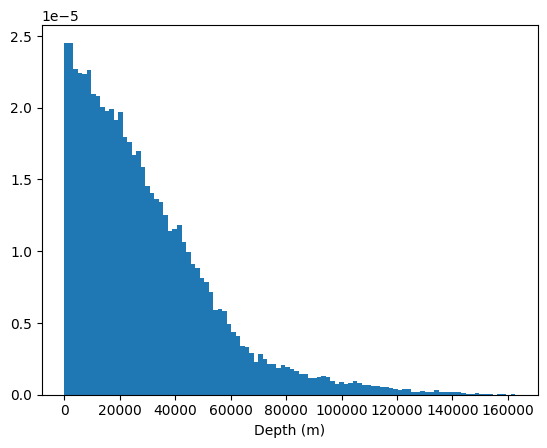

In [13]:
plt.hist(sample['Depth'], bins=100, density=True)
plt.xlabel('Depth (m)')

In [9]:
n_surf_samples = 5000
lon_surf = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_surf = rng.uniform(lat_min, lat_max, n_surf_samples)
z_surf = elev_interp(np.column_stack([lat_surf, lon_surf]))

q0_surf = q0_interp(np.column_stack([lat_surf, lon_surf]))
k0_surf = k0_interp(np.column_stack([lat_surf, lon_surf]))
A0_surf = A0_interp(np.column_stack([lat_surf, lon_surf]))

x_surf, y_surf = transformer.transform(lon_surf, lat_surf)

surf_sample = pd.DataFrame({
    "lon": lon_surf,
    "lat": lat_surf,
    "x": x_surf,
    "y": y_surf,
    "z": z_surf,
    "x_n": (x_surf - xyz_m[0]) / xyz_l[0],
    "y_n": (y_surf - xyz_m[1]) / xyz_l[1],
    "z_n": (z_surf - xyz_m[2]) / xyz_l[2],
    "Depth": 0,
    "Region": 0,
    "HeatFlow0": q0_surf,
    "ThermalConductivity0": k0_surf,
    "HeatProduction0": A0_surf,
    "Temperature": 10 + 273.15,
    "HeatFlow": q0_surf,
    "ThermalConductivity": k0_surf,
})

surf_sample

,lon,lat,x,y,z,x_n,y_n,z_n,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,Temperature,HeatFlow,ThermalConductivity
0,113.386070,34.539695,7.189678e+05,3.824585e+06,251.514100,0.573738,0.089847,0.990102,0,0,61.407290,2.765101,1.378891,283.15,61.407290,2.765101
1,107.688514,38.465459,2.110709e+05,4.262658e+06,1377.452715,0.114442,0.723698,0.997012,0,0,57.492601,2.312709,1.132981,283.15,57.492601,2.312709
2,115.423789,37.745334,8.898339e+05,4.186783e+06,27.092499,0.728254,0.613914,0.988725,0,0,57.006204,1.883999,1.496358,283.15,57.006204,1.883999
3,110.008295,39.045942,4.141812e+05,4.322343e+06,1235.920874,0.298117,0.810056,0.996143,0,0,66.203270,3.131818,0.989742,283.15,66.203270,3.131818
4,118.001396,36.719186,1.125686e+06,4.086644e+06,92.364736,0.941537,0.469022,0.989126,0,0,72.422241,2.790742,1.484237,283.15,72.422241,2.790742
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,116.665141,35.599303,1.013427e+06,3.954311e+06,43.846682,0.840021,0.277548,0.988828,0,0,71.021721,2.882666,1.481990,283.15,71.021721,2.882666
4996,115.051313,37.450148,8.584122e+05,4.152523e+06,27.043811,0.699839,0.564343,0.988725,0,0,54.291065,1.791189,1.486602,283.15,54.291065,1.791189
4997,107.505941,37.360025,1.905333e+05,4.140542e+06,1499.734683,0.095870,0.547008,0.997762,0,0,54.497546,2.232873,1.319484,283.15,54.497546,2.232873
4998,107.231802,34.726160,1.549162e+05,3.849146e+06,1271.118132,0.063661,0.125384,0.996359,0,0,54.812763,2.560201,1.646913,283.15,54.812763,2.560201


In [10]:
lon_cp = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_cp = rng.uniform(lat_min, lat_max, n_surf_samples)
z_cp = cp_interp(np.column_stack([lat_cp, lon_cp]))

q0_cp = q0_interp(np.column_stack([lat_cp, lon_cp]))
k0_cp = k0_interp(np.column_stack([lat_cp, lon_cp]))
A0_cp = A0_interp(np.column_stack([lat_cp, lon_cp]))
elev_cp = elev_interp(np.column_stack([lat_cp, lon_cp]))
sed_cp = sed_interp(np.column_stack([lat_cp, lon_cp]))
uc_cp = uc_interp(np.column_stack([lat_cp, lon_cp]))
mc_cp = mc_interp(np.column_stack([lat_cp, lon_cp]))
lc_cp = lc_interp(np.column_stack([lat_cp, lon_cp]))

depth_cp = elev_cp - z_cp

region_cp = np.where(z_cp >= sed_cp, 0,
            np.where(z_cp >= uc_cp, 1,
            np.where(z_cp >= mc_cp, 2, 
            np.where(z_cp >= lc_cp, 3, 4))))

x_cp, y_cp = transformer.transform(lon_cp, lat_cp)

cp_sample = pd.DataFrame({
    "lon": lon_cp,
    "lat": lat_cp,
    "x": x_cp,
    "y": y_cp,
    "z": z_cp,
    "x_n": (x_cp - xyz_m[0]) / xyz_l[0],
    "y_n": (y_cp - xyz_m[1]) / xyz_l[1],
    "z_n": (z_cp - xyz_m[2]) / xyz_l[2],
    "Depth": depth_cp,
    "Region": region_cp,
    "HeatFlow0": q0_cp,
    "ThermalConductivity0": k0_cp,
    "HeatProduction0": A0_cp,
    "Temperature": 580 + 273.15,
    "HeatFlow": np.where(depth_cp<1.3e4, q0_cp-A0_cp*depth_cp/1e3, q0_cp-A0_cp*13-A0_cp*(1-np.exp(-(depth_cp-1.3e4)/1.3e4))*13),
})

cp_sample

,lon,lat,x,y,z,x_n,y_n,z_n,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,Temperature,HeatFlow
0,117.766479,38.258560,1.092309e+06,4.256217e+06,-28038.802924,0.911354,0.714379,0.816495,28040.175141,2,66.406715,1.935893,1.412441,853.15,35.457067
1,117.871467,38.924790,1.095943e+06,4.330943e+06,-26784.852482,0.914641,0.822501,0.824190,26782.084866,2,65.824968,2.216221,1.339706,853.15,37.025577
2,112.932082,38.106209,6.693945e+05,4.219362e+06,-29494.039633,0.528909,0.661053,0.807564,30831.335915,2,58.882737,2.217360,1.432583,853.15,26.360195
3,109.510379,37.891718,3.690195e+05,4.194847e+06,-31207.149696,0.257277,0.625582,0.797052,32383.754133,2,67.329934,2.335928,1.159653,853.15,40.572973
4,115.371877,38.718433,8.801452e+05,4.294613e+06,-26366.641293,0.719493,0.769934,0.826756,26392.877382,2,64.987912,1.866152,1.398707,853.15,35.111623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,106.653776,35.011191,1.033230e+05,3.882926e+06,-31187.583512,0.017005,0.174261,0.797172,32829.259338,2,54.437630,2.316832,1.590635,853.15,17.579662
4996,110.037485,35.919514,4.131614e+05,3.975449e+06,-33791.184754,0.297195,0.308134,0.781194,35100.205092,2,71.709931,2.967401,1.554157,853.15,34.992735
4997,107.799853,34.592911,2.064878e+05,3.832556e+06,-27351.225483,0.110298,0.101381,0.820714,28350.309996,2,60.694874,2.461126,1.644491,853.15,24.502019
4998,110.406235,36.080407,4.465394e+05,3.993030e+06,-35030.752665,0.327379,0.333571,0.773587,35842.806690,2,69.756139,3.548420,1.526811,853.15,33.483685


In [11]:
lon_lab = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_lab = rng.uniform(lat_min, lat_max, n_surf_samples)
z_lab = lab_interp(np.column_stack([lat_lab, lon_lab]))

q0_lab = q0_interp(np.column_stack([lat_lab, lon_lab]))
k0_lab = k0_interp(np.column_stack([lat_lab, lon_lab]))
A0_lab = A0_interp(np.column_stack([lat_lab, lon_lab]))
elev_lab = elev_interp(np.column_stack([lat_lab, lon_lab]))

depth_lab = elev_lab - z_lab

x_lab, y_lab = transformer.transform(lon_lab, lat_lab)

lab_sample = pd.DataFrame({
    "lon": lon_lab,
    "lat": lat_lab,
    "x": x_lab,
    "y": y_lab,
    "z": z_lab,
    "x_n": (x_lab - xyz_m[0]) / xyz_l[0],
    "y_n": (y_lab - xyz_m[1]) / xyz_l[1],
    "z_n": (z_lab - xyz_m[2]) / xyz_l[2],
    "Depth": depth_lab,
    "Region": 4,
    "HeatFlow0": q0_lab,
    "ThermalConductivity0": k0_lab,
    "HeatProduction0": A0_lab,
    "Temperature": 1300 + 273.15,
    "HeatFlow": np.where(depth_lab<1.3e4, q0_lab-A0_lab*depth_lab/1e3, q0_lab-A0_lab*13-A0_lab*(1-np.exp(-(depth_lab-1.3e4)/1.3e4))*13),
})

lab_sample

,lon,lat,x,y,z,x_n,y_n,z_n,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,Temperature,HeatFlow
0,112.980075,36.987616,6.762176e+05,4.095331e+06,-78413.423980,0.535079,0.481591,0.507363,79502.190679,4,59.026281,2.245798,1.533158,1573.15,19.283820
1,112.950240,38.255036,6.706389e+05,4.235911e+06,-72589.907795,0.530034,0.684997,0.543100,74060.104613,4,58.866112,2.218740,1.431740,1573.15,21.810687
2,117.146543,36.396913,1.051499e+06,4.045566e+06,-63338.282175,0.874449,0.409585,0.599874,63628.545217,4,64.203735,2.646959,1.495994,1573.15,25.703716
3,107.710797,39.301131,2.163623e+05,4.355354e+06,-116514.099588,0.119227,0.857821,0.273553,117859.648509,4,59.442510,2.220744,1.000823,1573.15,33.425205
4,112.842250,38.397178,6.608747e+05,4.251491e+06,-71317.810154,0.521204,0.707540,0.550907,72283.404026,4,58.794330,2.218740,1.407932,1573.15,22.379527
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,110.726209,36.429908,4.754585e+05,4.031668e+06,-113371.677125,0.353530,0.389477,0.292837,114319.487671,4,68.927811,3.904752,1.512800,1573.15,29.603119
4996,110.843396,39.498568,4.865351e+05,4.372117e+06,-76115.554198,0.363547,0.882075,0.521464,77222.018187,4,64.646006,3.069730,1.054142,1573.15,37.336334
4997,108.765554,39.427181,3.076747e+05,4.366565e+06,-116580.014924,0.201802,0.874042,0.273148,117975.323539,4,63.981743,2.300849,0.831638,1573.15,42.362527
4998,106.836375,35.897245,1.241521e+05,3.980567e+06,-129044.349920,0.035841,0.315538,0.196659,130545.622240,4,54.830074,2.226515,1.552114,1573.15,14.477498


In [12]:
lon_moho = rng.uniform(lon_min, lon_max, n_surf_samples)
lat_moho = rng.uniform(lat_min, lat_max, n_surf_samples)
z_moho = moho_interp(np.column_stack([lat_moho, lon_moho]))

q0_moho = q0_interp(np.column_stack([lat_moho, lon_moho]))
k0_moho = k0_interp(np.column_stack([lat_moho, lon_moho]))
A0_moho = A0_interp(np.column_stack([lat_moho, lon_moho]))
elev_moho = elev_interp(np.column_stack([lat_moho, lon_moho]))
depth_moho = elev_moho - z_moho

x_moho, y_moho = transformer.transform(lon_moho, lat_moho)

moho_sample = pd.DataFrame({
    "lon": lon_moho,
    "lat": lat_moho,
    "x": x_moho,
    "y": y_moho,
    "z": z_moho,
    "x_n": (x_moho - xyz_m[0]) / xyz_l[0],
    "y_n": (y_moho - xyz_m[1]) / xyz_l[1],
    "z_n": (z_moho - xyz_m[2]) / xyz_l[2],
    "Depth": depth_moho,
    "Region": 3,
    "HeatFlow0": q0_moho,
    "ThermalConductivity0": k0_moho,
    "HeatProduction0": A0_moho,
    "HeatFlow": np.where(depth_moho<1.3e4, q0_moho-A0_moho*depth_moho/1e3, q0_moho-A0_moho*13-A0_moho*(1-np.exp(-(depth_moho-1.3e4)/1.3e4))*13),
})

moho_sample

,lon,lat,x,y,z,x_n,y_n,z_n,Depth,Region,HeatFlow0,ThermalConductivity0,HeatProduction0,HeatFlow
0,113.765412,36.504978,7.476697e+05,4.043518e+06,-36946.481894,0.599694,0.406622,0.761831,37663.947561,3,58.153239,2.142566,1.508426,21.875285
1,115.285848,37.450403,8.791696e+05,4.153471e+06,-32328.897784,0.718610,0.565715,0.790168,32356.516441,3,54.863106,1.806686,1.496358,20.346451
2,117.360053,36.923120,1.066787e+06,4.105287e+06,-34404.191349,0.888275,0.495996,0.777432,34439.845565,3,67.199132,2.524874,1.496976,32.018089
3,106.918961,37.494661,1.391713e+05,4.157579e+06,-43144.817383,0.049423,0.571658,0.723794,44626.102790,3,54.649166,2.278582,1.308211,22.128745
4,110.031759,39.123745,4.163038e+05,4.330955e+06,-43872.192443,0.300036,0.822517,0.719331,45103.175917,3,66.203270,3.131349,0.976920,41.878142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,107.331049,38.628469,1.805957e+05,4.281938e+06,-42272.638416,0.086883,0.751594,0.729147,43642.037012,3,58.211293,2.215953,1.112269,30.661556
4996,111.613878,35.767825,5.554894e+05,3.958371e+06,-39364.646385,0.425903,0.283423,0.746992,39911.095540,3,68.662986,3.190679,1.516254,31.727461
4997,107.619652,34.648825,1.901616e+05,3.839300e+06,-46168.047101,0.095534,0.111139,0.705242,47332.858015,3,58.247021,2.476096,1.646593,16.961626
4998,108.389205,35.379573,2.628387e+05,3.918267e+06,-43782.427166,0.161256,0.225397,0.719881,45107.711719,3,69.238465,2.540789,1.594080,29.545537


In [13]:
# 1) 取所有样本的 3D 归一化坐标
coords = sample[['x_n', 'y_n', 'z_n']].values   # (N,3)

# 2) 建 KNN（k 个邻居，+1 是因为第一个是自己）
k = 64
nns = NearestNeighbors(n_neighbors=k+1, algorithm='kd_tree')
nns.fit(coords)

dist, idx = nns.kneighbors(coords)
# idx: (N, k+1)，第 0 个是自身
neighbor_idx = idx[:, 1:]             # (N, k)

neighbor_idx_t = torch.tensor(neighbor_idx, dtype=torch.long, device=device)

In [3]:
class Net(nn.Module):
    def __init__(self, n=64, T0=800.0, dT=1000.0):
        super().__init__()
        self.T0 = T0
        self.dT = dT
        self.f = nn.Sequential(
            nn.Linear(3, n), nn.Tanh(),
            nn.Linear(n, n), nn.Tanh(),
            nn.Linear(n, n), nn.Tanh(),
            nn.Linear(n, 1)
        )

    def forward(self, x):
        theta = self.f(x)
        return self.T0 + self.dT * theta


In [15]:
def k_func(T, dh, k0, region):
    """ region: 0=sediment, 1=upper crust, 2=middle crust, 3=lower crust, 4=mantle """
    b = torch.tensor([1e-3, 1e-3, 5e-4, 1.5e-4, 0.0], device=T.device)[region].unsqueeze(1)
    c = 1.5e-3/1e3  # km^-1→m^-1
    k_crust = k0*(1+c*dh)/(1+b*(T-293.15))
    k_mantle = k0*(1.23e-10*T**3 + 1/(0.518+7.89e-4*T))
    mask = (region < 4).view(-1, 1)
    return torch.where(mask, k_crust, k_mantle)

def A_func(A0, dh, D0=1.3e4, D1=1.3e4):
    return torch.where(dh < D0, A0, A0*torch.exp(-(dh-D0)/D1))


In [16]:
def pde_residual(model, sample, debug=False):
    xyz_n = torch.tensor(sample[['x_n', 'y_n', 'z_n']].values, dtype=torch.float32, device=device, requires_grad=True)
    k0 = torch.tensor(sample['ThermalConductivity0'].values, device=device)[:, None]
    A0 = torch.tensor(sample['HeatProduction0'].values, device=device)[:, None]
    depth = torch.tensor(sample['Depth'].values, device=device)[:, None]
    region = torch.tensor(sample['Region'].values, dtype=torch.long, device=device)
    T = model(xyz_n)
    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0]
    k = k_func(T, depth, k0, region)
    A = A_func(A0, depth)
    div = 0
    for i in range(3):
        d = torch.autograd.grad(k*(gradT_n[:,i:i+1]/xyz_l[i]), xyz_n, torch.ones_like(T), create_graph=True)[0][:, i:i+1]
        div += d / xyz_l[i]
    div *= 1e6 # W/m^3 → μW/m^3，与 A 单位一致
    residual = (div + A)**2

    if debug:
        dTdx = gradT_n[:, 0:1] / xyz_l[0]
        dTdy = gradT_n[:, 1:2] / xyz_l[1]
        dTdz = gradT_n[:, 2:3] / xyz_l[2]
        print("\n==== PDE loss debug ====")
        print(f"T range: [{T.min().item():.2e}, {T.max().item():.2e}] K")
        print(f"dTdx range: [{dTdx.min().item()*1e3:.2e}, {dTdx.max().item()*1e3:.2e}] K/km")
        print(f"dTdy range: [{dTdy.min().item()*1e3:.2e}, {dTdy.max().item()*1e3:.2e}] K/km")
        print(f"dTdz range: [{dTdz.min().item()*1e3:.2e}, {dTdz.max().item()*1e3:.2e}] K/km")
        print(f"k range: [{k.min().item():.2e}, {k.max().item():.2e}] W/m/K")
        print(f"A range: [{A.min().item():.2e}, {A.max().item():.2e}] μW/m^3")
        print(f"div range: [{div.min().item():.2e}, {div.max().item():.2e}] μW/m^3")
        print(f"residual range: [{residual.min().item():.2e}, {residual.max().item():.2e}] (μW/m^3)^2")
        print(f"residual mean: {residual.mean().item():.2e} (μW/m^3)^2")
    
    return residual.mean()

def T_loss(model, df):
    xyz_n = torch.tensor(df[['x_n', 'y_n', 'z_n']].values, dtype=torch.float32, device=device)
    T = torch.tensor(df['Temperature'].values, dtype=torch.float32, device=device)[:, None]
    T_pred = model(xyz_n)
    return ((T_pred - T)**2).mean()

def q_loss(model, df, debug=False):
    xyz_n = torch.tensor(df[['x_n', 'y_n', 'z_n']].values, dtype=torch.float32, device=device, requires_grad=True)
    k0 = torch.tensor(df['ThermalConductivity0'].values, device=device)[:, None]
    q = torch.tensor(df['HeatFlow'].values, device=device)[:, None]
    depth = torch.tensor(df['Depth'].values, device=device)[:, None]
    region = torch.tensor(df['Region'].values, dtype=torch.long, device=device)
    T = model(xyz_n)
    dTdz = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0][:, 2:3] / xyz_l[2]
    k = k_func(T, depth, k0, region)
    q_pred = -k*dTdz*1e3
    residual = (q_pred - q)**2

    if debug:
        print("==== q loss debug ====")
        print(f"T range: [{T.min().item():.2e}, {T.max().item():.2e}] K")
        print(f"dTdz range: [{dTdz.min().item()*1e3:.2e}, {dTdz.max().item()*1e3:.2e}] K/km")
        print(f"q_pred range: [{q_pred.min().item():.2e}, {q_pred.max().item():.2e}] mW/m^2")
        print(f"residual range: [{residual.min().item():.2e}, {residual.max().item():.2e}] (mW/m^2)^2")
        print(f"residual mean: {residual.mean().item():.2e} (mW/m^2)^2")
    
    return residual.mean()


def knn_grad_smooth_loss(model, df, neighbor_idx_t):
    """
    用 K 近邻在 3D 空间上平滑 ∇T：
    对每个样本 i 和其邻居 j，惩罚 (gradT_i - gradT_j)^2。
    """

    # 1) 全量坐标 & 物理量
    xyz_n = torch.tensor(df[['x_n', 'y_n', 'z_n']].values, dtype=torch.float32, device=device, requires_grad=True)

    # 2) 网络输出 & 一阶梯度
    T = model(xyz_n)   # (N,1)

    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0] # (N,3)，对归一化坐标的梯度
    scale = torch.tensor(xyz_l, dtype=torch.float32, device=device).view(1, 3)
    gradT = gradT_n / scale

    N, k = neighbor_idx_t.shape

    # 3) 构造 i、j 的梯度张量
    # 每个 i 的索引 [i, i, ..., i] (k 次)
    idx_i = torch.arange(N, device=device).unsqueeze(1).expand(-1, k)  # (N,k)
    grad_i = gradT[idx_i]             # (N,k,3)
    grad_j = gradT[neighbor_idx_t]    # (N,k,3)

    diff = grad_i - grad_j            # (N,k,3)
    diff2 = (diff ** 2).sum(dim=2)    # (N,k)，每条边的 |Δ∇T|^2

    # 对每个点，把它与 k 个邻居的 diff2 求平均，然后乘权重再整体平均
    loss = diff2.mean(dim=1, keepdim=True).mean()
    return loss


In [17]:
model = Net(64).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for it in range(1, 4001):

    opt.zero_grad()
    stats = {}

    lpde    = pde_residual(model, sample) * 1e3
    lq      = q_loss(model, sample)
    lsurfT  = T_loss(model, surf_sample)
    lsurfq  = q_loss(model, surf_sample)
    lcpT    = T_loss(model, cp_sample)
    lcpq    = q_loss(model, cp_sample)
    llabT   = T_loss(model, lab_sample)
    llabq   = q_loss(model, lab_sample)
    lsmooth = knn_grad_smooth_loss(model, sample, neighbor_idx_t) * 1e3

    loss = (
        lpde
        + lsurfT + lsurfq
        + lcpT + lcpq
        + llabT
        + lsmooth
    )

    stats["loss"]    = loss
    stats["lpde"]    = lpde
    stats["lq"]      = lq
    stats["lsurfT"]  = lsurfT
    stats["lsurfq"]  = lsurfq
    stats["lcpT"]    = lcpT
    stats["lcpq"]    = lcpq
    stats["llabT"]   = llabT
    stats["llabq"]   = llabq
    stats["lsmooth"] = lsmooth

    loss.backward()
    opt.step()

    if it % 200 == 0:
        print(
            f"{it}: total={stats['loss'].item():.3e}, "
            f"pde={stats['lpde'].item():.3e}, "
            f"q={stats['lq'].item():.3e}, "
            f"surfT={stats['lsurfT'].item():.3e}, "
            f"surfq={stats['lsurfq'].item():.3e}, "
            f"cpT={stats['lcpT'].item():.3e}, "
            f"cpq={stats['lcpq'].item():.3e}, "
            f"labT={stats['llabT'].item():.3e}, "
            f"labq={stats['llabq'].item():.3e}, "
            f"smooth={stats['lsmooth'].item():.3e}"
        )


KeyboardInterrupt: 

In [18]:
model.train()

opt = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=20,
    history_size=100,
    line_search_fn="strong_wolfe",
)

for it in range(4001, 5001):
    stats = {}

    def closure():
        opt.zero_grad()

        # PDE loss
        lpde    = pde_residual(model, sample) * 1e3
        lq      = q_loss(model, sample)
        lsurfT  = T_loss(model, surf_sample)
        lsurfq  = q_loss(model, surf_sample)
        lcpT    = T_loss(model, cp_sample)
        lcpq    = q_loss(model, cp_sample)
        llabT   = T_loss(model, lab_sample)
        llabq   = q_loss(model, lab_sample)
        lsmooth = knn_grad_smooth_loss(model, sample, neighbor_idx_t) * 1e3

        loss = (
            lpde
            + lsurfT + lsurfq
            + lcpT + lcpq
            + llabT + llabq
            + lsmooth
        )

        loss.backward()

        stats["loss"]    = loss
        stats["lpde"]    = lpde
        stats["lq"]      = lq
        stats["lsurfT"]  = lsurfT
        stats["lsurfq"]  = lsurfq
        stats["lcpT"]    = lcpT
        stats["lcpq"]    = lcpq
        stats["llabT"]   = llabT
        stats["llabq"]   = llabq
        stats["lsmooth"] = lsmooth

        return loss

    opt.step(closure)
    print(
        f"{it}: total={stats['loss'].item():.3e}, "
        f"pde={stats['lpde'].item():.3e}, "
        f"q={stats['lq'].item():.3e}, "
        f"surfT={stats['lsurfT'].item():.3e}, "
        f"surfq={stats['lsurfq'].item():.3e}, "
        f"cpT={stats['lcpT'].item():.3e}, "
        f"cpq={stats['lcpq'].item():.3e}, "
        f"labT={stats['llabT'].item():.3e}, "
        f"labq={stats['llabq'].item():.3e}, "
        f"smooth={stats['lsmooth'].item():.3e}"
    )


4001: total=2.748e+03, pde=6.102e+02, q=1.906e+02, surfT=6.872e+01, surfq=1.230e+02, cpT=1.060e+03, cpq=9.719e+01, labT=3.720e+02, labq=4.160e+02, smooth=3.620e-03
4002: total=2.677e+03, pde=6.200e+02, q=1.886e+02, surfT=6.403e+01, surfq=1.295e+02, cpT=9.474e+02, cpq=1.163e+02, labT=4.136e+02, labq=3.858e+02, smooth=3.785e-03
4003: total=2.620e+03, pde=6.591e+02, q=1.919e+02, surfT=7.151e+01, surfq=1.264e+02, cpT=8.521e+02, cpq=1.330e+02, labT=3.870e+02, labq=3.907e+02, smooth=4.030e-03
4004: total=2.530e+03, pde=6.438e+02, q=1.893e+02, surfT=8.040e+01, surfq=1.335e+02, cpT=7.776e+02, cpq=1.286e+02, labT=3.680e+02, labq=3.985e+02, smooth=3.988e-03
4005: total=2.432e+03, pde=5.430e+02, q=1.831e+02, surfT=8.320e+01, surfq=1.310e+02, cpT=7.999e+02, cpq=1.227e+02, labT=3.492e+02, labq=4.034e+02, smooth=3.624e-03
4006: total=2.383e+03, pde=5.309e+02, q=1.843e+02, surfT=1.130e+02, surfq=1.331e+02, cpT=7.413e+02, cpq=1.185e+02, labT=3.412e+02, labq=4.046e+02, smooth=3.624e-03
4007: total=2.31

KeyboardInterrupt: 

In [19]:
# 保存模型
torch.save(model.state_dict(), "model-test04.pth")

In [4]:
model = Net(64).to(device)
model.load_state_dict(torch.load("model-test04.pth"))
model.eval()


Net(
  (f): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [5]:
def predict_fields(lon, lat, z):
    """
    输入:
        lon, lat, z: 1D 或广播后能拉直的一维数组，长度相同
            lon, lat 单位: 度
            z 单位: m (和 sample['z'] 一样，向下为负数)
    输出:
        字典 { 'T', 'q', 'k', 'A', 'pde', 'depth_km', 'lon', 'lat', 'z' }
        其中 q 单位 mW/m^2, A 单位 μW/m^3,
        pde 单位 (μW/m^3)^2（对应 pde_residual 中的 (div + A)^2）
    """
    lon = np.asarray(lon).ravel()
    lat = np.asarray(lat).ravel()
    z   = np.asarray(z).ravel()
    assert lon.shape == lat.shape == z.shape

    # 插值地表及分层信息
    pts   = np.column_stack([lat, lon])  # 注意前面你用的是 [lat, lon]
    k0    = k0_interp(pts)               # W/m/K
    A0    = A0_interp(pts)               # μW/m^3 (和 pde 中一致)
    elev  = elev_interp(pts)             # m
    sed   = sed_interp(pts)
    uc    = uc_interp(pts)
    mc    = mc_interp(pts)
    lc    = lc_interp(pts)
    cp    = cp_interp(pts)
    lab   = lab_interp(pts)

    # 分层编码 (和 sample 中保持一致)
    region = np.where(z >= sed, 0,
              np.where(z >= uc, 1,
              np.where(z >= mc, 2,
              np.where(z >= lc, 3, 4))))

    # 坐标投影 + 归一化
    x, y = transformer.transform(lon, lat)  # EPSG:32649
    x_n = (x - xyz_m[0]) / xyz_l[0]
    y_n = (y - xyz_m[1]) / xyz_l[1]
    z_n = (z - xyz_m[2]) / xyz_l[2]

    xyz_n = torch.tensor(
        np.column_stack([x_n, y_n, z_n]),
        dtype=torch.float32, device=device, requires_grad=True
    )

    # 物性张量
    k0_t   = torch.tensor(k0,  dtype=torch.float32, device=device)[:, None]
    A0_t   = torch.tensor(A0,  dtype=torch.float32, device=device)[:, None]
    region_t = torch.tensor(region, dtype=torch.long, device=device)
    elev_t = torch.tensor(elev, dtype=torch.float32, device=device)[:, None]
    z_t    = torch.tensor(z,    dtype=torch.float32, device=device)[:, None]

    # 前向：温度
    T = model(xyz_n)  # K

    # 梯度 -> dT/dz (K/m)
    gradT_n = torch.autograd.grad(T, xyz_n, torch.ones_like(T), create_graph=True)[0]
    dTdz = gradT_n[:, 2:3] / xyz_l[2]

    # k(T, depth), A(depth)
    k  = k_func(T, elev_t - z_t, k0_t, region_t) # W/m/K
    A  = A_func(A0_t, elev_t - z_t)              # μW/m^3

    # 热流 (mW/m^2) = -k dT/dz * 1e3
    q = -k * dTdz * 1e3

    depth_km = (elev - z) / 1e3

    # PDE 残差 (与 pde_residual 中一致): (div + A)^2, 单位约 (μW/m^3)^2
    div = 0
    for i in range(3):
        # gradT_n 是对归一化坐标 xyz_n 的梯度，这里要除以对应的尺度 xyz_l[i]
        comp = k * (gradT_n[:, i:i+1] / xyz_l[i])
        d = torch.autograd.grad( comp, xyz_n, torch.ones_like(T), create_graph=True)[0][:, i:i+1]
        div += d / xyz_l[i]
    div = div * 1e6  # 转为 μW/m^3

    pde_res = (div + A) ** 2  # (μW/m^3)^2

    out = {
        "lon": lon,
        "lat": lat,
        "z": z,
        "depth_km": depth_km,
        "T": T.detach().cpu().numpy().reshape(lon.shape),
        "q": q.detach().cpu().numpy().reshape(lon.shape),
        "k": k.detach().cpu().numpy().reshape(lon.shape),
        "A": A.detach().cpu().numpy().reshape(lon.shape),
        "pde": pde_res.detach().cpu().numpy().reshape(lon.shape),
        "elev": elev,
        "sed": sed,
        "uc": uc,
        "mc": mc,
        "lc": lc,
        "cp": cp,
        "lab": lab,
        "region": region,
    }
    return out


In [18]:
lon_min, lon_max, dlon = 106.5, 118.5, 0.25
lat_min, lat_max, dlat = 34.0, 40.0, 0.25
ddepth_km = 2.0  # 深度步长（km）

lons = np.arange(lon_min, lon_max + 1e-12, dlon)
lats = np.arange(lat_min, lat_max + 1e-12, dlat)

lon_all, lat_all, depth_all = [], [], []

for lat0 in lats:
    for lon0 in lons:
        pts = np.array([[lat0, lon0]])  # [lat, lon]
        elev0 = float(elev_interp(pts)[0])  # m
        lab0 = float(lab_interp(pts)[0])    # m
        lab_depth_km = (elev0 - lab0) / 1e3

        if not np.isfinite(lab_depth_km) or lab_depth_km <= 0:
            continue

        d = np.arange(0.0, lab_depth_km, ddepth_km)
        if (len(d) == 0) or (abs(d[-1] - lab_depth_km) > 1e-9):
            d = np.append(d, lab_depth_km)

        n = len(d)
        lon_all.append(np.full(n, lon0))
        lat_all.append(np.full(n, lat0))
        depth_all.append(d)

lon = np.concatenate(lon_all)
lat = np.concatenate(lat_all)
depth_km = np.concatenate(depth_all)

pts = np.column_stack([lat, lon])  # [lat, lon]
elev = elev_interp(pts)            # m
z = elev - depth_km * 1e3          # m

pred = predict_fields(lon, lat, z)

out = pd.DataFrame({
    "Lon": lon,
    "Lat": lat,
    "Depth_km": depth_km,
    "Temperature_K": pred["T"],
    "Thermal_Conductivity_W_mK": pred["k"],
    "Heat_Production_W_m3": pred["A"] * 1e-6,  # A: μW/m^3 -> W/m^3
    "Heat_Flux_mW_m2": pred["q"],
})

out.to_csv("result-test04.csv", index=False)
print("rows:", len(out))
print("result-test04.csv")


rows: 55515
result-test04.csv


In [18]:
def plot_vertical_profile(lon0, lat0, nz=200):
    """
    在指定经纬度 (lon0, lat0) 处，绘制 T/q/k/A 随深度变化的 1D 剖面，
    并在图上标出 cp、sed、uc、mc、lc 的深度（横虚线）。
    """
    # ---- 1) 该点的地表 / 界面深度 ----
    pts = np.array([[lat0, lon0]])  # 注意顺序 [lat, lon]
    elev0 = elev_interp(pts)[0]    # 地表 z (m)
    lab0  = lab_interp(pts)[0]     # LAB z (m)
    z_col = np.linspace(elev0, lab0, nz)  # z (m)

    # ---- 2) 调用通用预测函数 ----
    out = predict_fields(lon=np.full(nz, lon0), lat=np.full(nz, lat0), z=z_col)
    depth_km = out["depth_km"]
    T_prof   = out["T"]
    q_prof   = out["q"]
    k_prof   = out["k"]
    A_prof   = out["A"]
    pde_prof = out["pde"]

    elev0 = out["elev"]
    sed_depth_km = ((elev0 - out["sed"]) / 1e3)[0]
    uc_depth_km  = ((elev0 - out["uc"]) / 1e3)[0]
    mc_depth_km  = ((elev0 - out["mc"]) / 1e3)[0]
    lc_depth_km  = ((elev0 - out["lc"]) / 1e3)[0]
    cp_depth_km  = ((elev0 - out["cp"]) / 1e3)[0]
    lab_depth_km = ((elev0 - out["lab"]) / 1e3)[0]

    idx = np.argsort(depth_km)
    depth_km = depth_km[idx]
    T_prof   = T_prof[idx]
    q_prof   = q_prof[idx]
    k_prof   = k_prof[idx]
    A_prof   = A_prof[idx]
    pde_prof = pde_prof[idx]

    # ---- 3) 画图 ----
    fig, axes = plt.subplots(1, 5, figsize=(16, 5), sharey=True)

    # 温度
    axes[0].plot(T_prof, depth_km)
    axes[0].set_xlabel("T (K)")
    axes[0].set_ylabel("Depth (km)")
    axes[0].invert_yaxis()
    axes[0].grid(True)

    # 热流
    axes[1].plot(q_prof, depth_km)
    axes[1].set_xlabel("q (mW/m²)")
    axes[1].grid(True)

    # 热导率
    axes[2].plot(k_prof, depth_km)
    axes[2].set_xlabel("k (W/m/K)")
    axes[2].grid(True)

    # 生热率
    axes[3].plot(A_prof, depth_km)
    axes[3].set_xlabel("A (μW/m³)")
    axes[3].grid(True)

    # PDE loss
    axes[4].plot(pde_prof, depth_km)
    axes[4].set_xlabel("PDE loss ((μW/m³)²)")
    axes[4].grid(True)

    # ---- 5) 在所有子图上画分层 / cp 的横虚线 ----
    interface_depths = [
        (sed_depth_km, "sed"),
        (uc_depth_km,  "uc"),
        (mc_depth_km,  "mc"),
        (lc_depth_km,  "lc"),
        (cp_depth_km,  "cp"),
        (lab_depth_km, "LAB"),
    ]

    for ax in axes:
        for d_km, label in interface_depths:
            if np.nanmin(depth_km) <= d_km <= np.nanmax(depth_km):
                ax.axhline(d_km, linestyle="--", linewidth=0.8)
                ax.text(0.98, d_km, label, transform=ax.get_yaxis_transform(), ha="right", va="center")

    fig.suptitle(f"Vertical profile at lon={lon0:.2f}°, lat={lat0:.2f}°")
    plt.tight_layout()
    plt.show()


In [72]:
def plot_vertical_profile_fan(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    n_locs=200,          # 随机采样点数
    depth_max_km=7.0,    # 最大深度（km）
    nz=60,               # 垂直采样层数
    seed=42
):
    """
    五联图版本：T, q, k, A, PDE 的扇形图 + 红色平均曲线 + 平均界面深度 (sed, uc, mc, lc, cp, LAB)
    """

    rng = np.random.default_rng(seed)

    # -------- 1) 随机采样经纬度 --------
    lon_s = rng.uniform(lon_min, lon_max, n_locs)
    lat_s = rng.uniform(lat_min, lat_max, n_locs)

    # 深度网格（向下为正）
    depth_km = np.linspace(0.0, depth_max_km, nz)
    depth_m  = depth_km * 1e3

    # (n_locs, nz)
    T_all   = np.full((n_locs, nz), np.nan)
    q_all   = np.full((n_locs, nz), np.nan)
    k_all   = np.full((n_locs, nz), np.nan)
    A_all   = np.full((n_locs, nz), np.nan)
    pde_all = np.full((n_locs, nz), np.nan)

    # 每个点的界面深度 (km)
    sed_list = []
    uc_list  = []
    mc_list  = []
    lc_list  = []
    cp_list  = []
    lab_list = []

    # -------- 2) 对每个采样点计算剖面 --------
    for i, (lon0, lat0) in enumerate(zip(lon_s, lat_s)):
        pts   = np.array([[lat0, lon0]])
        elev0 = elev_interp(pts)[0]
        sed0  = sed_interp(pts)[0]
        uc0   = uc_interp(pts)[0]
        mc0   = mc_interp(pts)[0]
        lc0   = lc_interp(pts)[0]
        cp0   = cp_interp(pts)[0]
        lab0  = lab_interp(pts)[0]

        sed_list.append((elev0 - sed0) / 1e3)
        uc_list.append((elev0 - uc0)   / 1e3)
        mc_list.append((elev0 - mc0)   / 1e3)
        lc_list.append((elev0 - lc0)   / 1e3)
        cp_list.append((elev0 - cp0)   / 1e3)
        lab_list.append((elev0 - lab0) / 1e3)

        # z 坐标
        z_col = elev0 - depth_m

        out = predict_fields(
            lon=np.full(nz, lon0),
            lat=np.full(nz, lat0),
            z=z_col
        )

        T_all[i]   = out["T"]
        q_all[i]   = out["q"]
        k_all[i]   = out["k"]
        A_all[i]   = out["A"]
        pde_all[i] = out["pde"]

        # LAB 以下深度掩掉
        lab_depth_km = lab_list[-1]
        mask = depth_km > lab_depth_km
        T_all[i, mask]   = np.nan
        q_all[i, mask]   = np.nan
        k_all[i, mask]   = np.nan
        A_all[i, mask]   = np.nan
        pde_all[i, mask] = np.nan

    # -------- 3) 计算平均曲线 --------
    T_mean   = np.nanmean(T_all,   axis=0)
    q_mean   = np.nanmean(q_all,   axis=0)
    k_mean   = np.nanmean(k_all,   axis=0)
    A_mean   = np.nanmean(A_all,   axis=0)
    pde_mean = np.nanmean(pde_all, axis=0)

    # -------- 4) 平均界面深度 --------
    sed_avg = np.nanmean(sed_list)
    uc_avg  = np.nanmean(uc_list)
    mc_avg  = np.nanmean(mc_list)
    lc_avg  = np.nanmean(lc_list)
    cp_avg  = np.nanmean(cp_list)
    lab_avg = np.nanmean(lab_list)

    interfaces = [
        (sed_avg, "sed"),
        (uc_avg,  "uc"),
        (mc_avg,  "mc"),
        (lc_avg,  "lc"),
        (cp_avg,  "cp"),
        (lab_avg, "LAB"),
    ]

    # -------- 5) 画五联图 --------
    fig, axes = plt.subplots(1, 5, figsize=(16, 5), sharey=True)

    def plot_fan(ax, all_vals, mean_vals, xlabel):
        # 灰色扇形
        for i in range(n_locs):
            ax.plot(all_vals[i], depth_km, color="0.7", alpha=0.15, linewidth=0.8)

        # 红色平均曲线（无 marker）
        ax.plot(mean_vals, depth_km, color="red", linewidth=2.0)

        # 界面横线
        for d_km, label in interfaces:
            if 0 <= d_km <= depth_max_km:
                ax.axhline(d_km, linestyle="--", linewidth=1, color="black", alpha=0.7)
                ax.text(0.98, d_km, label,
                        transform=ax.get_yaxis_transform(),
                        ha="right", va="center",
                        fontsize=9)

        ax.set_xlabel(xlabel)
        ax.grid(True, alpha=0.3)

    # T
    plot_fan(axes[0], T_all, T_mean, "T (K)")
    axes[0].set_ylabel("Depth (km)")
    axes[0].invert_yaxis()

    # q
    plot_fan(axes[1], q_all, q_mean, "q (mW/m²)")

    # k
    plot_fan(axes[2], k_all, k_mean, "k (W/m/K)")

    # A
    plot_fan(axes[3], A_all, A_mean, "A (μW/m³)")

    # PDE
    plot_fan(axes[4], pde_all, pde_mean, "PDE loss")
    axes[4].set_xlim(0, 3)

    fig.suptitle(
        f"Vertical profile fan (N={n_locs})   "
        f"[{lon_min:.1f}–{lon_max:.1f}E,  {lat_min:.1f}–{lat_max:.1f}N]"
    )
    plt.tight_layout()
    plt.show()

    return {
        "depth_km": depth_km,
        "T_all": T_all, "q_all": q_all, "k_all": k_all,
        "A_all": A_all, "pde_all": pde_all,
        "T_mean": T_mean, "q_mean": q_mean, "k_mean": k_mean,
        "A_mean": A_mean, "pde_mean": pde_mean,
        "sed_avg": sed_avg, "uc_avg": uc_avg,
        "mc_avg": mc_avg, "lc_avg": lc_avg,
        "cp_avg": cp_avg, "lab_avg": lab_avg,
        "lon_samples": lon_s, "lat_samples": lat_s,
    }


In [73]:
def plot_section(lon1, lat1, lon2, lat2, nx=200, nz=80, field="T"):
    """
    在 (lon1, lat1) - (lon2, lat2) 之间画一条剖面线，做 T/q/k/A/pde 剖面图，
    并在图上叠加 cp、sed、uc、mc、lc 界面的虚线（随距离变化的曲线）。
    
    field 取值: "T", "q", "k", "A", "pde"
    """
    # ---------------- 1) 沿线采样经纬度 ----------------
    lon_line = np.linspace(lon1, lon2, nx)
    lat_line = np.linspace(lat1, lat2, nx)

    # 对应的插值点
    pts_line   = np.column_stack([lat_line, lon_line])  # 注意 [lat, lon]
    elev_line  = elev_interp(pts_line)  # 地表 z (m)
    lab_line   = lab_interp(pts_line)   # LAB z (m)

    # 各界面 z (m)
    sed_line   = sed_interp(pts_line)
    uc_line    = uc_interp(pts_line)
    mc_line    = mc_interp(pts_line)
    lc_line    = lc_interp(pts_line)
    cp_line    = cp_interp(pts_line)

    # 把它们转成“深度”（相对地表，向下为正，单位 km）
    sed_depth_km = (elev_line - sed_line) / 1e3
    uc_depth_km  = (elev_line - uc_line)  / 1e3
    mc_depth_km  = (elev_line - mc_line)  / 1e3
    lc_depth_km  = (elev_line - lc_line)  / 1e3
    cp_depth_km  = (elev_line - cp_line)  / 1e3
    lab_depth_km = (elev_line - lab_line) / 1e3

    # ---------------- 2) 构造 2D 网格并预测物理量 ----------------
    lon_cols = []
    lat_cols = []
    z_cols   = []

    for i in range(nx):
        # 从地表到 LAB/200km 均匀取 nz 个点
        z_col = np.linspace(elev_line[i], lab_line[i], nz)
        # z_col = np.linspace(elev_line[i], -200_000, nz)
        z_cols.append(z_col)
        lon_cols.append(np.full(nz, lon_line[i]))
        lat_cols.append(np.full(nz, lat_line[i]))

    lon_grid = np.stack(lon_cols, axis=1)  # (nz, nx)
    lat_grid = np.stack(lat_cols, axis=1)
    z_grid   = np.stack(z_cols,   axis=1)

    # 通用预测函数
    out = predict_fields(
        lon_grid.ravel(), lat_grid.ravel(), z_grid.ravel()
    )
    F = out[field].reshape(nz, nx)  # 物理量

    # 深度网格 (km)
    depth_grid_km = (elev_line[np.newaxis, :] - z_grid) / 1e3  # (nz, nx)

    # ---------------- 3) 剖面距离（km） ----------------
    x_line, y_line = transformer.transform(lon_line, lat_line)
    dist = np.sqrt((x_line - x_line[0])**2 + (y_line - y_line[0])**2) / 1e3  # km
    dist_2d = np.tile(dist, (nz, 1))  # (nz, nx)

    # ---------------- 4) 画剖面主图 ----------------
    fig, ax = plt.subplots(figsize=(9, 4))
    pcm = ax.pcolormesh(
        dist_2d, depth_grid_km, F, shading="auto"
    )
    ax.invert_yaxis()
    ax.set_xlabel("Distance along profile (km)")
    ax.set_ylabel("Depth (km)")

    title_map = {
        "T": "Temperature (K)",
        "q": "Heat flow (mW/m²)",
        "k": "Thermal conductivity (W/m/K)",
        "A": "Heat production (μW/m³)",
        "pde": "PDE loss ((μW/m³)²)",
    }
    ax.set_title(title_map.get(field, field))

    cbar = fig.colorbar(pcm, ax=ax)
    cbar.set_label(title_map.get(field, field))

    # ---------------- 5) 叠加界面虚线 ----------------
    # 只画在当前剖面深度范围内的部分
    min_depth = np.nanmin(depth_grid_km)
    max_depth = np.nanmax(depth_grid_km)

    def mask_depth(d):
        d = d.copy()
        d[(d < min_depth) | (d > max_depth)] = np.nan
        return d

    sed_d = mask_depth(sed_depth_km)
    uc_d  = mask_depth(uc_depth_km)
    mc_d  = mask_depth(mc_depth_km)
    lc_d  = mask_depth(lc_depth_km)
    cp_d  = mask_depth(cp_depth_km)
    lab_d = mask_depth(lab_depth_km)

    ax.plot(dist, sed_d, linestyle="--", linewidth=1, label="sed")
    ax.plot(dist, uc_d,  linestyle="--", linewidth=1, label="uc")
    ax.plot(dist, mc_d,  linestyle="--", linewidth=1, label="mc")
    ax.plot(dist, lc_d,  linestyle="--", linewidth=1, label="lc")
    ax.plot(dist, cp_d,  linestyle="--", linewidth=1, label="cp")
    ax.plot(dist, lab_d, linestyle="--", linewidth=1, label="LAB")

    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


In [74]:
def plot_depth_slice(depth_km, nx=200, ny=200, field="T"):
    """
    在给定深度 (相对地表, km) 处绘制 T/q/k/A/pde 切片图。
    depth_km > 0 表示向下的深度。
    nx, ny: 经向 / 纬向网格分辨率
    """
    # 构造经纬度规则网格
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_grid, lat_grid = np.meshgrid(lon_vec, lat_vec)

    # 地表高程
    pts = np.column_stack([lat_grid.ravel(), lon_grid.ravel()])
    elev = elev_interp(pts)  # m

    # 指定深度的实际 z 坐标 (m)：地表以下 depth_km
    z = elev - depth_km * 1e3

    # 调用通用预测
    out = predict_fields(lon_grid.ravel(), lat_grid.ravel(), z)
    F = out[field].reshape(ny, nx)

    # 画图
    plt.figure(figsize=(9, 4))
    pcm = plt.pcolormesh(
        lon_vec, lat_vec, F, shading="auto"
    )
    plt.xlabel("Longitude (°)")
    plt.ylabel("Latitude (°)")
    title_map = {
        "T": f"Temperature (K) at {depth_km:.1f} km depth",
        "q": f"Heat flow (mW/m²) at {depth_km:.1f} km depth",
        "k": f"Thermal conductivity (W/m/K) at {depth_km:.1f} km depth",
        "A": f"Heat production (μW/m³) at {depth_km:.1f} km depth",
        "pde": f"PDE loss ((μW/m³)²) at {depth_km:.1f} km depth",
    }
    plt.title(title_map.get(field, field))

    cbar = plt.colorbar(pcm)
    if field == "T":
        cbar.set_label("Temperature (K)")
    elif field == "q":
        cbar.set_label("Heat flow (mW/m²)")
    elif field == "k":
        cbar.set_label("Thermal conductivity (W/m/K)")
    elif field == "A":
        cbar.set_label("Heat production (μW/m³)")
    elif field == "pde":
        cbar.set_label("PDE loss ((μW/m³)²)")
    plt.tight_layout()
    plt.show()


In [103]:
def plot_T1300_isotherm_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=200, ny=200, nz=200,
    T_iso_C=1300
):
    """
    3D 绘图：X=lon, Y=lat, Z=depth(km, downward positive)
    绘制 1300°C 等温面 + LAB
    """

    # --------- 1) 水平网格 ---------
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_2d, lat_2d = np.meshgrid(lon_vec, lat_vec)

    # 插值地形 & LAB (m)
    pts = np.column_stack([lat_2d.ravel(), lon_2d.ravel()])
    elev = elev_interp(pts).reshape(ny, nx)
    lab  = lab_interp(pts).reshape(ny, nx)

    # --------- 2) 构造更深的垂向网格 ---------
    # 让底部比 LAB 再深 20 km
    z_bottom = np.full_like(lab, -200000)  # lab - 20000   # m

    s = np.linspace(0, 1, nz)[:, None, None]
    z_3d = elev[None,:,:] + s*(z_bottom[None,:,:] - elev[None,:,:])

    lon_3d = np.broadcast_to(lon_2d[None,:,:], z_3d.shape)
    lat_3d = np.broadcast_to(lat_2d[None,:,:], z_3d.shape)

    # --------- 3) 预测温度 ---------
    out = predict_fields(lon_3d.ravel(), lat_3d.ravel(), z_3d.ravel())
    T_3d = out["T"].reshape(z_3d.shape)

    # --------- 4) 找 1300°C 等温面 ---------
    T_iso_K = T_iso_C + 273.15
    z_iso = np.full((ny, nx), np.nan)

    for j in range(ny):
        for i in range(nx):

            T_col = T_3d[:, j, i]
            z_col = z_3d[:, j, i]

            mask = T_col >= T_iso_K
            if not np.any(mask):
                continue

            k = np.argmax(mask)

            if k == 0:
                z_star = z_col[0]
            else:
                z1, z2 = z_col[k-1], z_col[k]
                T1, T2 = T_col[k-1], T_col[k]
                frac = (T_iso_K - T1)/(T2 - T1)
                z_star = z1 + frac*(z2 - z1)

            z_iso[j, i] = z_star

    # --------- 5) 深度 km（向下为正）---------
    depth_iso = (elev - z_iso)/1e3
    depth_lab = (elev - lab)/1e3

    # --------- 6) 绘制 3D 图 ---------
    fig = plt.figure(figsize=(10,7))
    ax = fig.add_subplot(111, projection="3d")

    ax.set_box_aspect((1, 1, 0.3))   # ← 压扁 Z 轴（重点）

    # 1300°C 等温面：暖色
    depth_iso_plot = np.ma.masked_invalid(depth_iso)
    surf_iso = ax.plot_surface(
        lon_2d, lat_2d, depth_iso_plot,
        cmap="turbo_r",
        linewidth=0.1, edgecolor="k",
        antialiased=True, alpha=0.95
    )
    fig.colorbar(surf_iso, ax=ax, shrink=0.5).set_label("1300°C Depth (km)")

    # LAB：冷色透明面
    # ax.plot_surface(
    #     lon_2d, lat_2d, depth_lab,
    #     color="cyan", alpha=0.3, linewidth=0
    # )

    # 坐标轴
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_zlabel("Depth (km)")
    ax.invert_zaxis()

    ax.set_title("LAB Depth / 1300°C Isotherm")

    ax.view_init(elev=25, azim=-120)
    plt.tight_layout()
    plt.show()

    # --------- 7) 绘制 LAB 深度二维图 ---------
    fig2, ax2 = plt.subplots(figsize=(8, 4))

    lab_plot = np.ma.masked_invalid(depth_lab)

    # 颜色图可以选择 magma_r、viridis、turbo、cividis 等
    im = ax2.contourf(
        lon_2d, lat_2d, lab_plot,
        levels=50,
        cmap="turbo_r"
    )

    cbar = fig2.colorbar(im, ax=ax2)
    cbar.set_label("LAB Depth (km)")

    ax2.set_xlabel("Longitude (°)")
    ax2.set_ylabel("Latitude (°)")
    ax2.set_title("LAB Depth Map (2D)")

    plt.tight_layout()
    plt.show()

    return depth_iso, depth_lab


In [95]:
def plot_moho_temperature_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=200, ny=200
):
    """
    3D/2D 绘图：X=lon, Y=lat, Z=Moho depth(km, downward positive)
    3D：莫霍面（Z 为深度），颜色为莫霍温度(°C)
    2D：莫霍面温度平面图
    """

    # --------- 1) 水平网格 ---------
    lon_vec = np.linspace(lon_min, lon_max, nx)
    lat_vec = np.linspace(lat_min, lat_max, ny)
    lon_2d, lat_2d = np.meshgrid(lon_vec, lat_vec)

    # 插值地形 & Moho (m)
    pts = np.column_stack([lat_2d.ravel(), lon_2d.ravel()])
    elev = elev_interp(pts).reshape(ny, nx)         # 地形高程
    z_moho = moho_interp(pts).reshape(ny, nx)       # Moho 高程

    # --------- 2) Moho 深度 km（向下为正）---------
    depth_moho = (elev - z_moho) / 1e3              # km, downward positive

    # --------- 3) 在 Moho 面上预测温度 ----------
    out = predict_fields(lon_2d.ravel(), lat_2d.ravel(), z_moho.ravel())
    T_moho_K = out["T"].reshape(ny, nx)
    T_moho_C = T_moho_K - 273.15                    # ℃

    depth_moho_plot = np.ma.masked_invalid(depth_moho)
    T_moho_plot = np.ma.masked_invalid(T_moho_C)

    # =====================================================
    # 4) 3D 曲面图：Moho 深度 + 温度着色（风格跟 LAB 一致）
    # =====================================================
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.set_box_aspect((1, 1, 0.3))   # 压扁 Z 轴（和 LAB 一样）

    cmap = plt.cm.get_cmap("turbo")
    norm = plt.Normalize(T_moho_plot.min(), T_moho_plot.max())
    facecolors = cmap(norm(T_moho_plot))

    surf_moho = ax.plot_surface(
        lon_2d, lat_2d, depth_moho_plot,
        facecolors=facecolors,
        linewidth=0.1, edgecolor="k",
        antialiased=True, alpha=0.95
    )

    # 为 colorbar 构造 mappable（颜色条显示温度，而不是深度）
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(T_moho_plot)
    fig.colorbar(mappable, ax=ax, shrink=0.5).set_label("Moho Temperature (°C)")

    # 坐标轴
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_zlabel("Moho Depth (km)")
    ax.invert_zaxis()

    ax.set_title("Moho Depth / Moho Temperature")

    ax.view_init(elev=25, azim=-120)   # 和 LAB 一样的视角
    plt.tight_layout()
    plt.show()

    # =====================================================
    # 5) 2D 平面图：Moho 温度
    # =====================================================
    fig2, ax2 = plt.subplots(figsize=(8, 4))

    im = ax2.contourf(
        lon_2d, lat_2d, T_moho_plot,
        levels=50,
        cmap="turbo"
    )

    cbar = fig2.colorbar(im, ax=ax2)
    cbar.set_label("Moho Temperature (°C)")

    ax2.set_xlabel("Longitude (°)")
    ax2.set_ylabel("Latitude (°)")
    ax2.set_title("Moho Temperature Map at Moho Depth (2D)")

    plt.tight_layout()
    plt.show()

    return T_moho_C, depth_moho


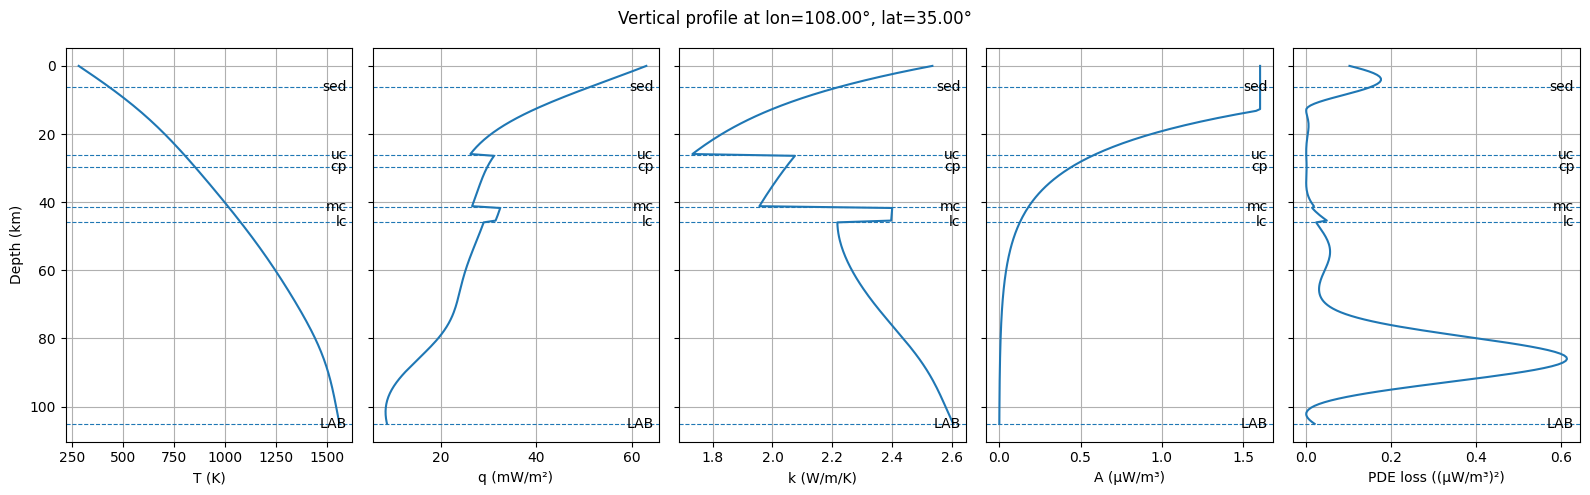

In [77]:
plot_vertical_profile(108.0, 35.0)

C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\263046421.py:81: RuntimeWarning: Mean of empty slice
  T_mean   = np.nanmean(T_all,   axis=0)
C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\263046421.py:82: RuntimeWarning: Mean of empty slice
  q_mean   = np.nanmean(q_all,   axis=0)
C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\263046421.py:83: RuntimeWarning: Mean of empty slice
  k_mean   = np.nanmean(k_all,   axis=0)
C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\263046421.py:84: RuntimeWarning: Mean of empty slice
  A_mean   = np.nanmean(A_all,   axis=0)
C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\263046421.py:85: RuntimeWarning: Mean of empty slice
  pde_mean = np.nanmean(pde_all, axis=0)


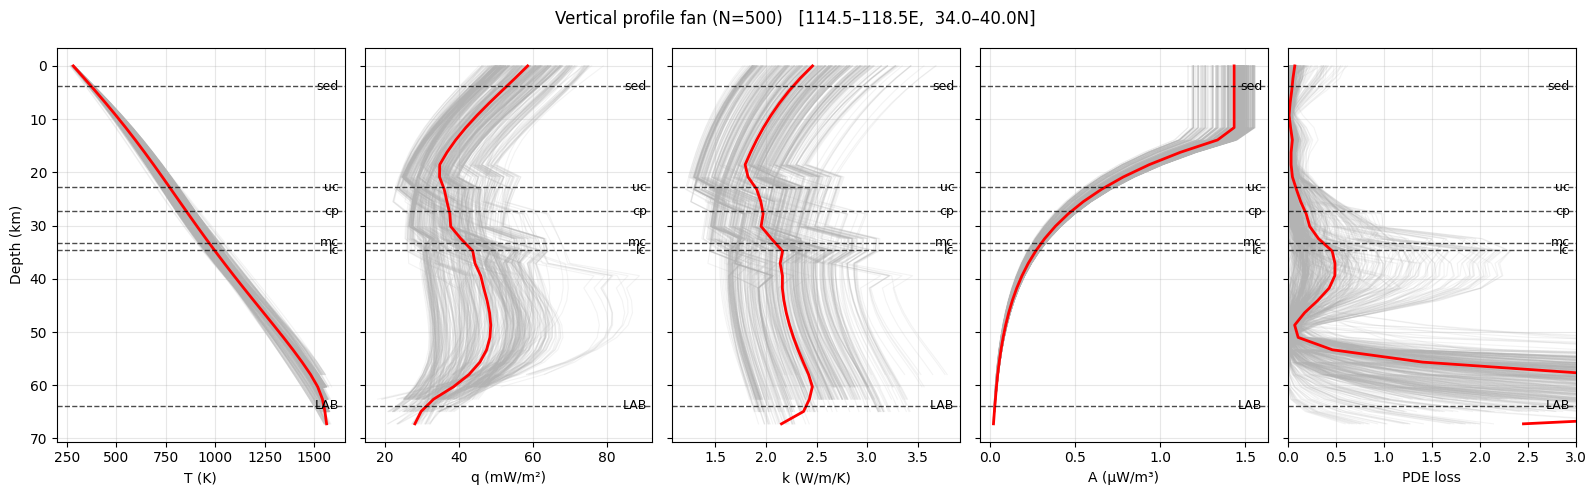

In [78]:
res = plot_vertical_profile_fan(
    lon_min=114.5, lon_max=118.5,
    lat_min=34.0, lat_max=40.0,
    n_locs=500,
    depth_max_km=160.0,
    nz=70
)

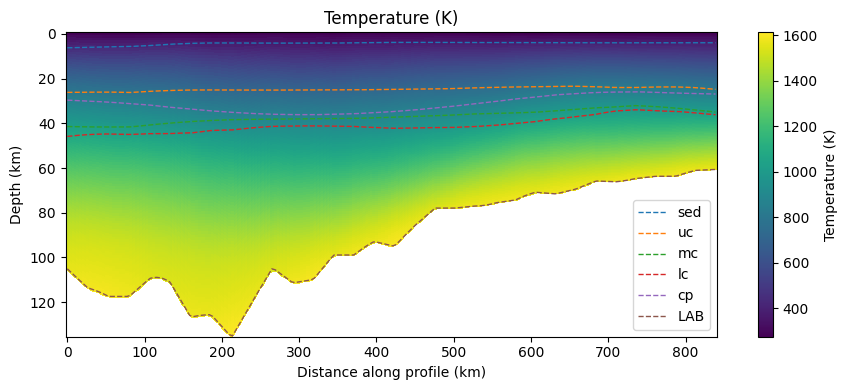

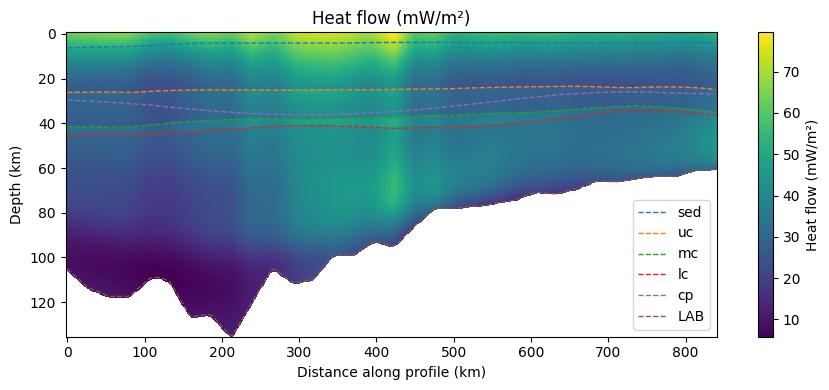

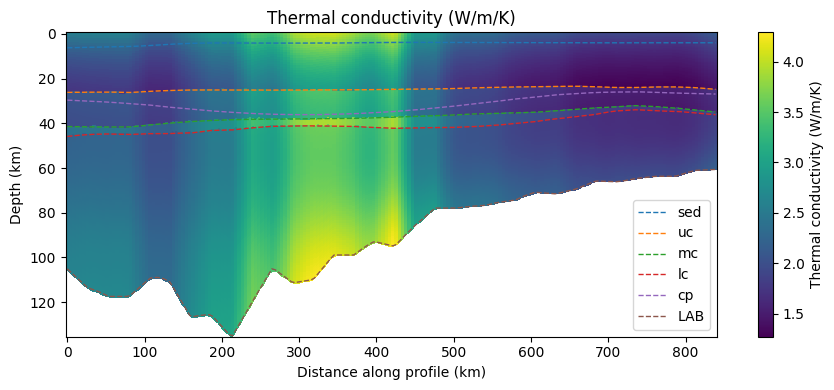

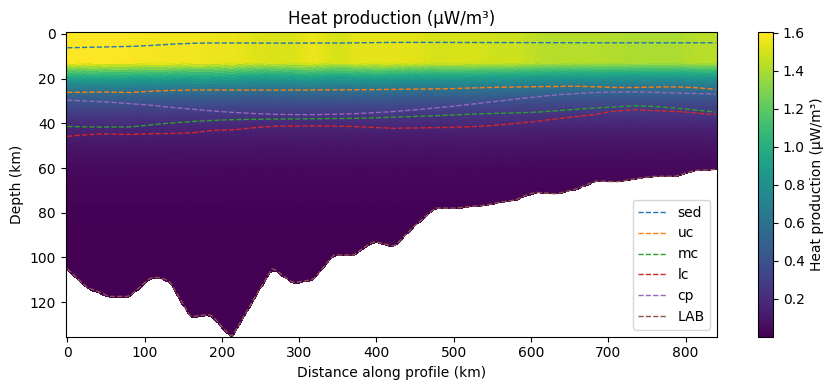

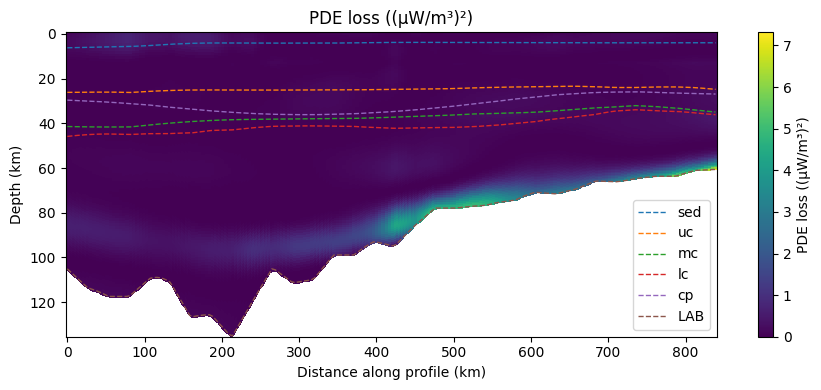

In [79]:
# 比如：从 (108E, 35N) 到 (116E, 39N) 的温度、热流、热导率、生热率剖面
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="T")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="q")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="k")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="A")
plot_section(108.0, 35.0, 116.0, 39.0, nx=200, nz=100, field="pde")


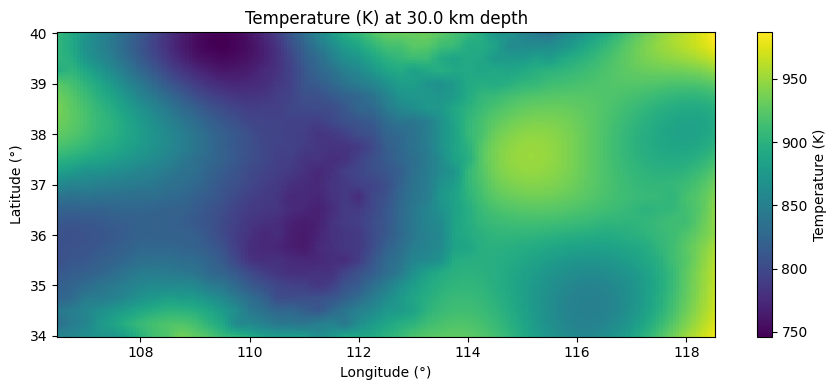

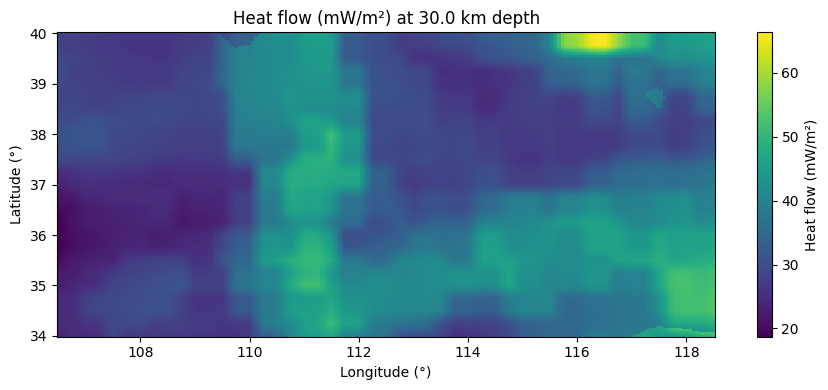

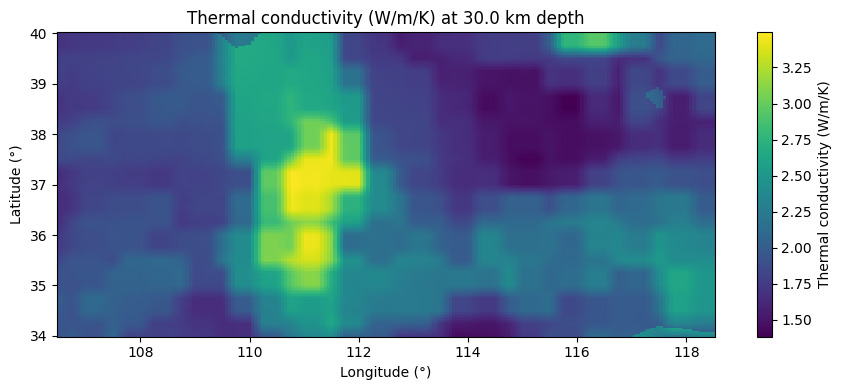

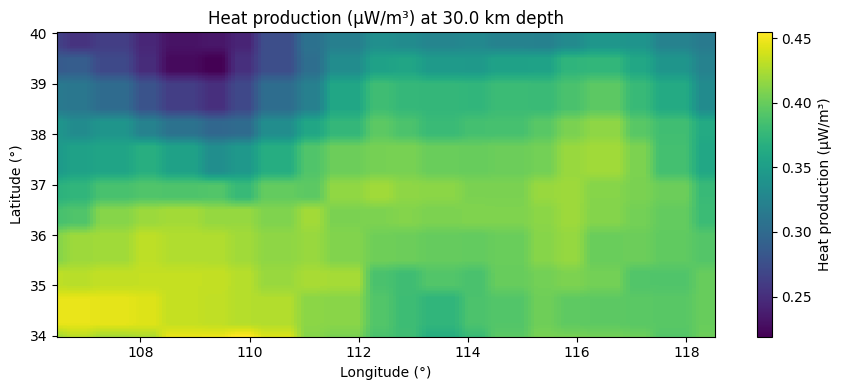

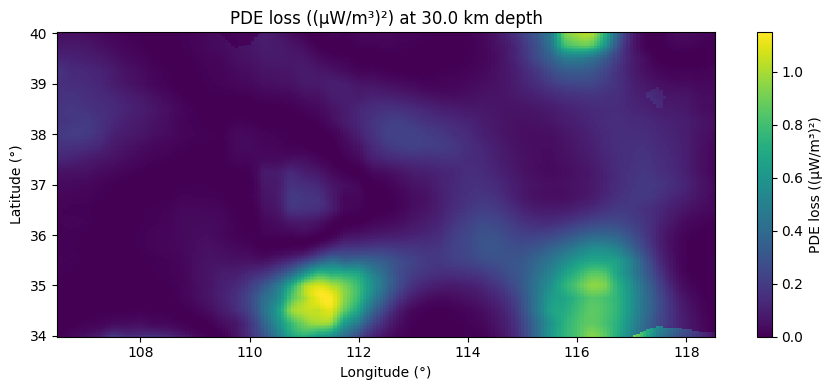

In [80]:
# 20 km 深度处的温度切片
plot_depth_slice(30.0, nx=200, ny=200, field="T")
plot_depth_slice(30.0, nx=200, ny=200, field="q")
plot_depth_slice(30.0, nx=200, ny=200, field="k")
plot_depth_slice(30.0, nx=200, ny=200, field="A")
plot_depth_slice(30.0, nx=200, ny=200, field="pde")


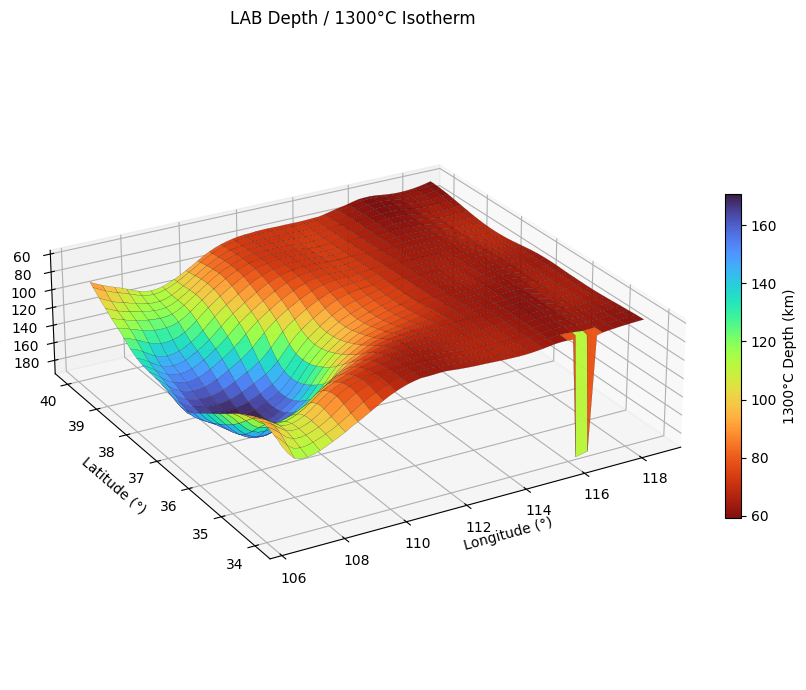

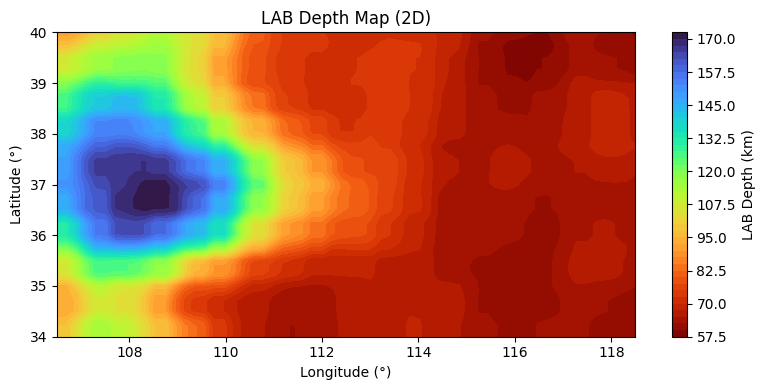

In [108]:
result = plot_T1300_isotherm_3d_ll(
    lon_min=106.5, lon_max=118.5,
    lat_min=34.0,  lat_max=40.0,
    nx=60, ny=60, nz=80,
    T_iso_C=1300.0
)


C:\Users\hjjfr\AppData\Local\Temp\ipykernel_45880\3602331726.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("turbo")


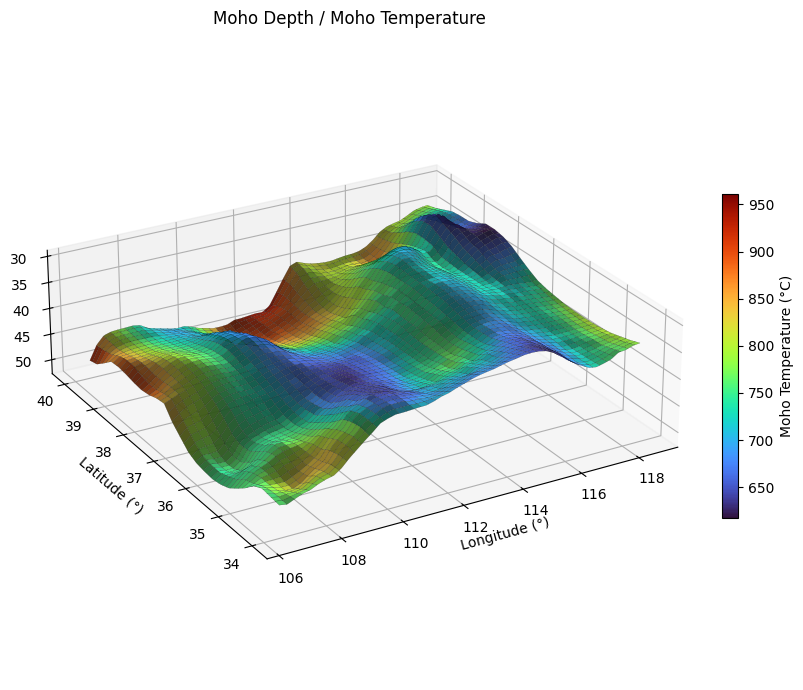

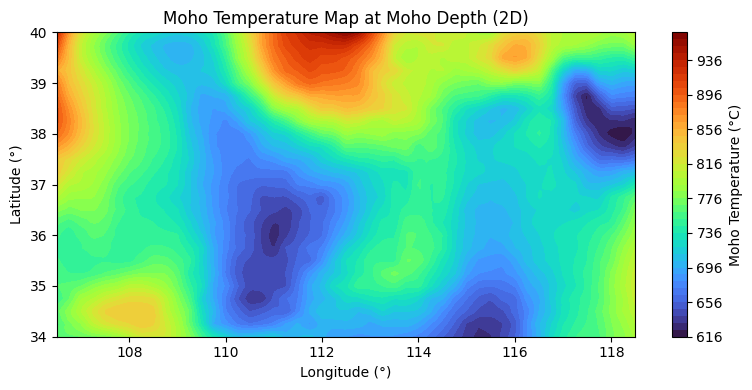

In [96]:
T_moho_C, depth_moho = plot_moho_temperature_3d_ll()

In [19]:
# predict samples
df = pd.read_csv('sample-test05.csv')

result = predict_fields(df['lon'].values, df['lat'].values, df['z'].values)

df['T_baseline'] = result['T']
df['q_baseline'] = result['q']
df['k_baseline'] = result['k']
df['A_baseline'] = result['A']
df['pde_baseline'] = result['pde']

df.to_csv('sample-test05-baseline.csv', index=False)

In [ ]:
# 清空缓存
torch.cuda.empty_cache()